# Algorithm comparison on BED-BPP (task O3DBP-3-2)

This notebook compares the packing algorithms of this repository on the benchmark metric and explains where the
improvements come from.

**The benchmark score.** An item counts only if (a) the whole pile of its order stays stable in the Blender rigid body
simulation (no object moves more than 1 cm vertically) and (b) its bottom is not above 2 m. The score is the number of
counted items divided by the number of all items in the orders. One falling item makes its whole order count 0.

**Datasets.**

| name | orders | role |
|---|---|---|
| `sample5` | the 5 orders of `example_data/5_bed-bpp.json` | the examples run in this repository |
| `dev20` | 20 orders sampled from `bed-bpp_v1.json` (seed 2026) | tuning of the hyperparameters |
| `val20` | 20 other sampled orders | first held out; it revealed that the tuning on `dev20` overfitted (see the tuning log), and was then used to diagnose the collapses and to choose the slenderness limit |
| `test20` | 20 further orders (seed 7), disjoint from all others | untouched until the final evaluation: the unbiased estimate for new orders |

All subsets are small samples of the 10,003 orders; differences of a few hundredths are within the noise of 20 orders.

**Algorithms** (task O3DBP-3-2: the robot sees the next 3 items and may choose one of the next 2).

| algorithm | description |
|---|---|
| `o3dbp_original` | the original heuristic `heuristics/o3dbp_3_2.py` |
| `o3dbp_constrained` | same heuristic, but corner points are no longer shifted outwards, no fallback to the origin, placements need an estimated support of at least 75 %, and no item starts above 2 m |
| `stable_heightmap_basic` | new heuristic `heuristics/stable_heightmap.py`: exhaustive search on a 5 mm grid, support >= 60 % with the center of mass over the support, one-step lookahead |
| `stable_heightmap_load_check` | adds the pile model `heuristics/load_stability.py`: the load of all boxes above must rest within each box's support (catches leaning towers), which allows support >= 30 % |
| `stable_heightmap_tuned` | load check with tuned score weights and stability margin, plus a limit on the slenderness of box columns (the defaults of `StableHeightmapHeuristic`) |

**Reproduce** a result (conda env `bed-bpp-env`, repository root):

```
PYTHONPATH=src python experiments/run_experiment.py --algorithm stable_heightmap_tuned --data example_data/5_bed-bpp.json --dataset sample5
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch, Rectangle

RESULTS = Path("results")
DATASETS = ["sample5", "dev20", "val20", "test20"]
ALGORITHMS = [
    "o3dbp_original",
    "o3dbp_constrained",
    "stable_heightmap_basic",
    "stable_heightmap_load_check",
    "stable_heightmap_tuned",
]

runs = {}
for dataset in DATASETS:
    for algorithm in ALGORITHMS:
        path = RESULTS / dataset / f"{algorithm}.json"
        if path.exists():
            runs[(dataset, algorithm)] = json.loads(path.read_text())

from run_experiment import ALGORITHMS as PRESETS  # experiments/run_experiment.py

LABELS = {a: PRESETS[a]["label"] for a in ALGORITHMS}

rows = []
for (dataset, algorithm), run in runs.items():
    per_order = pd.DataFrame(run["per_order"])
    items = per_order["items"].sum()
    rows.append(
        {
            "dataset": dataset,
            "algorithm": algorithm,
            "score": run["score"],
            "stable orders": f'{run["stable_orders"]}/{run["orders"]}',
            "placed %": 100 * per_order["placed"].sum() / items,
            "counted %": 100 * per_order["counted"].sum() / items,
            "mean pile height (m)": per_order["max_top_mm"].mean() / 1000,
            "volume utilization": per_order["volume_utilization"].mean(),
            "solve ms / item": 1000 * per_order["solve_s"].sum() / max(per_order["placed"].sum(), 1),
        }
    )
summary = pd.DataFrame(rows)
summary["algorithm"] = pd.Categorical(summary["algorithm"], ALGORITHMS, ordered=True)
summary["dataset"] = pd.Categorical(summary["dataset"], DATASETS, ordered=True)
summary = summary.sort_values(["dataset", "algorithm"]).reset_index(drop=True)

## Summary

All metrics per dataset and algorithm. *counted %* equals the score; *placed %* includes items in piles that collapsed.

In [2]:
summary.round(
    {
        "score": 3,
        "placed %": 1,
        "counted %": 1,
        "mean pile height (m)": 2,
        "volume utilization": 2,
        "solve ms / item": 0,
    }
).set_index(["dataset", "algorithm"])

score stable orders  placed %  counted %  \
dataset algorithm                                                               
sample5 o3dbp_original               0.115           1/5      95.0       11.5   
        o3dbp_constrained            0.310           5/5      31.0       31.0   
        stable_heightmap_basic       0.720           5/5      72.0       72.0   
        stable_heightmap_load_check  0.875           5/5      87.5       87.5   
        stable_heightmap_tuned       0.825           5/5      82.5       82.5   
dev20   o3dbp_original               0.011          1/20      93.9        1.1   
        o3dbp_constrained            0.285         19/20      31.1       28.5   
        stable_heightmap_basic       0.716         20/20      71.6       71.6   
        stable_heightmap_load_check  0.649         17/20      82.3       64.9   
        stable_heightmap_tuned       0.819         20/20      81.9       81.9   
val20   o3dbp_original               0.010          1/20      94.6        1.0   
        o3dbp_constrained            0.260         19/20      27.0       26.0   
        stable_heightmap_basic       0.614         16/20      78.1       61.4   
        stable_heightmap_load_check  0.670         16/20      82.3       67.0   
        stable_heightmap_tuned       0.564         15/20      79.0       56.4   
test20  o3dbp_original               0.000          0/20      91.0        0.0   
        o3dbp_constrained            0.253         20/20      25.3       25.3   
        stable_heightmap_basic       0.524         17/20      64.1       52.4   
        stable_heightmap_load_check  0.619         17/20      76.0       61.9   
        stable_heightmap_tuned       0.552         16/20      73.4       55.2   

                                     mean pile height (m)  volume utilization  \
dataset algorithm                                                               
sample5 o3dbp_original                               3.12                0.44   
        o3dbp_constrained                            1.39                0.32   
        stable_heightmap_basic                       2.04                0.47   
        stable_heightmap_load_check                  2.16                0.59   
        stable_heightmap_tuned                       2.17                0.55   
dev20   o3dbp_original                               3.14                0.45   
        o3dbp_constrained                            1.22                0.40   
        stable_heightmap_basic                       1.93                0.53   
        stable_heightmap_load_check                  2.15                0.55   
        stable_heightmap_tuned                       2.15                0.56   
val20   o3dbp_original                               3.12                0.45   
        o3dbp_constrained                            1.06                0.40   
        stable_heightmap_basic                       2.14                0.53   
        stable_heightmap_load_check                  2.14                0.56   
        stable_heightmap_tuned                       2.14                0.54   
test20  o3dbp_original                               3.23                0.44   
        o3dbp_constrained                            0.92                0.44   
        stable_heightmap_basic                       2.09                0.48   
        stable_heightmap_load_check                  2.15                0.55   
        stable_heightmap_tuned                       2.10                0.56   

                                     solve ms / item  
dataset algorithm                                     
sample5 o3dbp_original                        2557.0  
        o3dbp_constrained                     1642.0  
        stable_heightmap_basic                 197.0  
        stable_heightmap_load_check            170.0  
        stable_heightmap_tuned                 237.0  
dev20   o3dbp_original                        3208.0  
        o3dbp_constrained      

In [3]:
# chart style: reference palette (light mode), hairline grid, text in ink colors
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
ACCENT, CONTEXT = "#2a78d6", "#b9b7ae"  # emphasis: the tuned algorithm in blue, the others in gray
LIGHT_STEP, DARK_STEP = "#86b6ef", "#1c5cab"  # two shades of the blue ramp
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "xtick.color": MUTED,
        "ytick.color": INK_2,
        "text.color": INK,
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": False,
        "figure.dpi": 110,
    }
)


def hbar(ax, y, value, height, color, radius_px=4):
    # horizontal bar with a 4 px rounded data-end and a square baseline end (call after the limits are set)
    if value <= 0:
        return
    box = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    rx = min(radius_px * (x1 - x0) / box.width, value / 2)
    ry = min(radius_px * (y1 - y0) / box.height, height / 2)
    ax.add_patch(FancyBboxPatch((0, y - height / 2), value, height, boxstyle=f"round,pad=0,rounding_size={rx}",
                                mutation_aspect=ry / rx, linewidth=0, facecolor=color))
    ax.add_patch(Rectangle((0, y - height / 2), max(value - rx, 0), height, linewidth=0, facecolor=color))


def style_value_axis(ax, xlim, label):
    ax.set_xlim(*xlim)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel(label)

## Score by algorithm

The tuned algorithm (blue) against the earlier steps (gray). `test20` was not used for any decision.

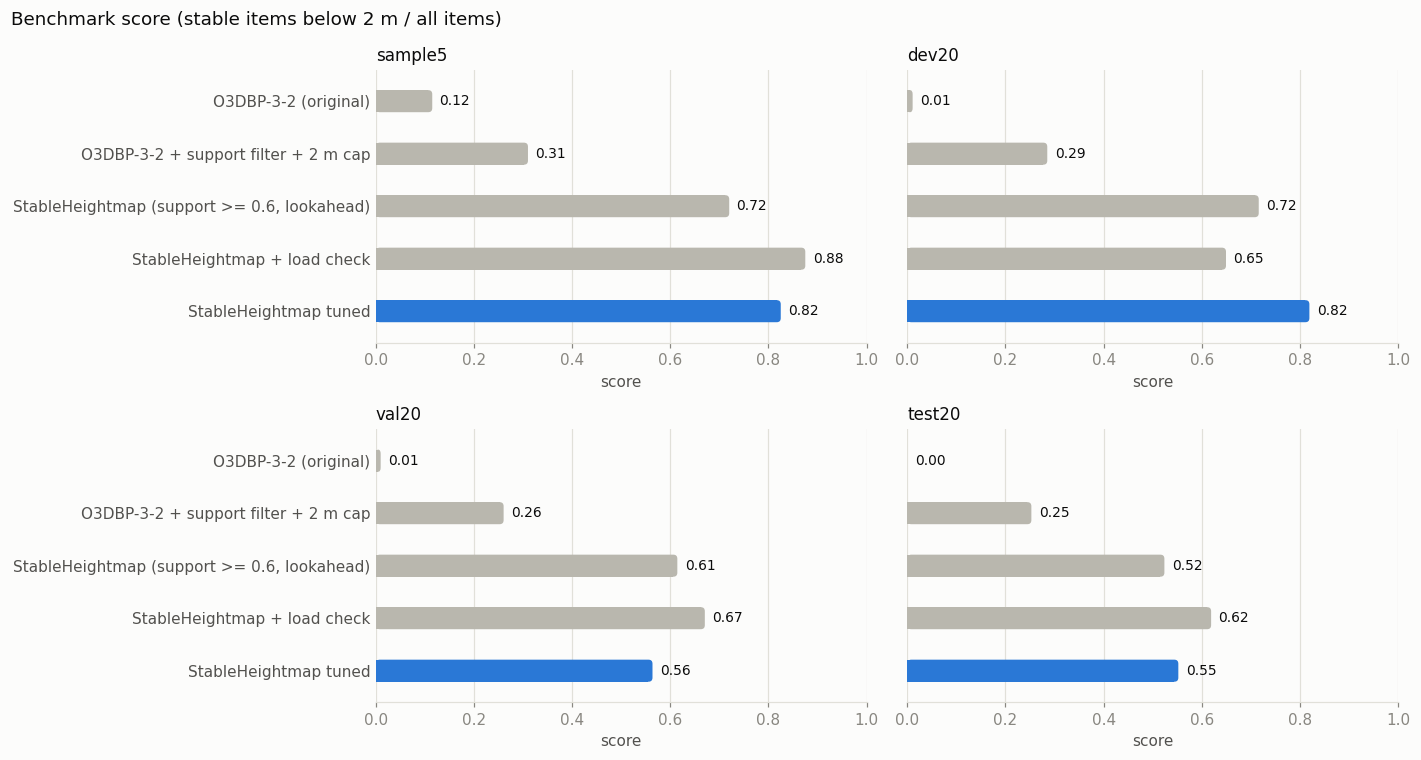

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
axes = axes.ravel()
names = [LABELS[a] for a in ALGORITHMS][::-1]
for ax, dataset in zip(axes, DATASETS):
    ax.set_yticks(range(len(ALGORITHMS)), names)
    ax.set_ylim(-0.6, len(ALGORITHMS) - 0.4)
    style_value_axis(ax, (0, 1.0), "score")
    ax.set_title(dataset, loc="left", color=INK, fontsize=11)
fig.suptitle("Benchmark score (stable items below 2 m / all items)", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
fig.canvas.draw()  # final axes sizes, needed for the rounded bar ends
for ax, dataset in zip(axes, DATASETS):
    for y, algorithm in enumerate(ALGORITHMS[::-1]):
        run = runs.get((dataset, algorithm))
        if run is None:
            continue
        color = ACCENT if algorithm == "stable_heightmap_tuned" else CONTEXT
        hbar(ax, y, run["score"], 0.42, color)
        ax.text(run["score"] + 0.015, y, f'{run["score"]:.2f}', va="center", color=INK, fontsize=9)
plt.show()

## Where the items are lost

*placed* = items in the packing plan, *counted* = items that count for the score. The gap between the two dots are items in piles that collapsed in the simulation; where no pile collapsed, the dots coincide and only the dark one is visible. The original heuristic places almost everything, but most piles collapse; the new heuristics place fewer items, but keep almost all piles stable.

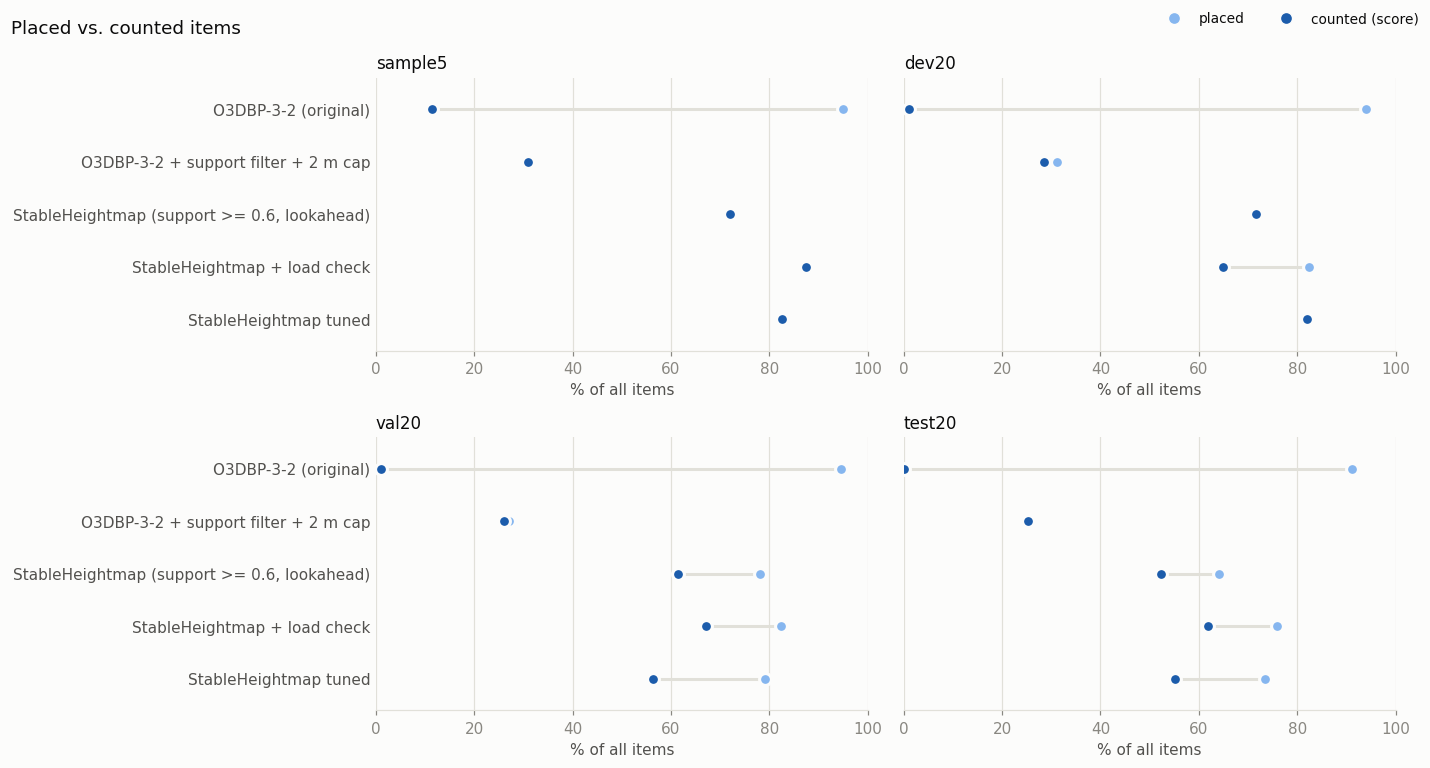

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
axes = axes.ravel()
for ax, dataset in zip(axes, DATASETS):
    for y, algorithm in enumerate(ALGORITHMS[::-1]):
        row = summary[(summary.dataset == dataset) & (summary.algorithm == algorithm)]
        if row.empty:
            continue
        placed, counted = float(row["placed %"].iloc[0]), float(row["counted %"].iloc[0])
        ax.plot([counted, placed], [y, y], color=GRID, linewidth=2, solid_capstyle="round", zorder=1)
        ax.scatter([placed], [y], s=60, color=LIGHT_STEP, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.scatter([counted], [y], s=60, color=DARK_STEP, edgecolor=SURFACE, linewidth=2, zorder=4)
    ax.set_yticks(range(len(ALGORITHMS)), names)
    ax.set_ylim(-0.6, len(ALGORITHMS) - 0.4)
    style_value_axis(ax, (0, 100), "% of all items")
    ax.set_title(dataset, loc="left", color=INK, fontsize=11)
from matplotlib.lines import Line2D

handles = [
    Line2D([], [], marker="o", linestyle="", markersize=8, color=LIGHT_STEP, markeredgecolor=SURFACE, label="placed"),
    Line2D([], [], marker="o", linestyle="", markersize=8, color=DARK_STEP, markeredgecolor=SURFACE,
           label="counted (score)"),
]
fig.legend(handles=handles, loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.suptitle("Placed vs. counted items", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()

## Pile heights

The highest point of each order's pile; one dot per order. Items whose bottom is above 2 m never count, so piles far above 2 m mean wasted, risky items. The new heuristics never start an item above 2 m.

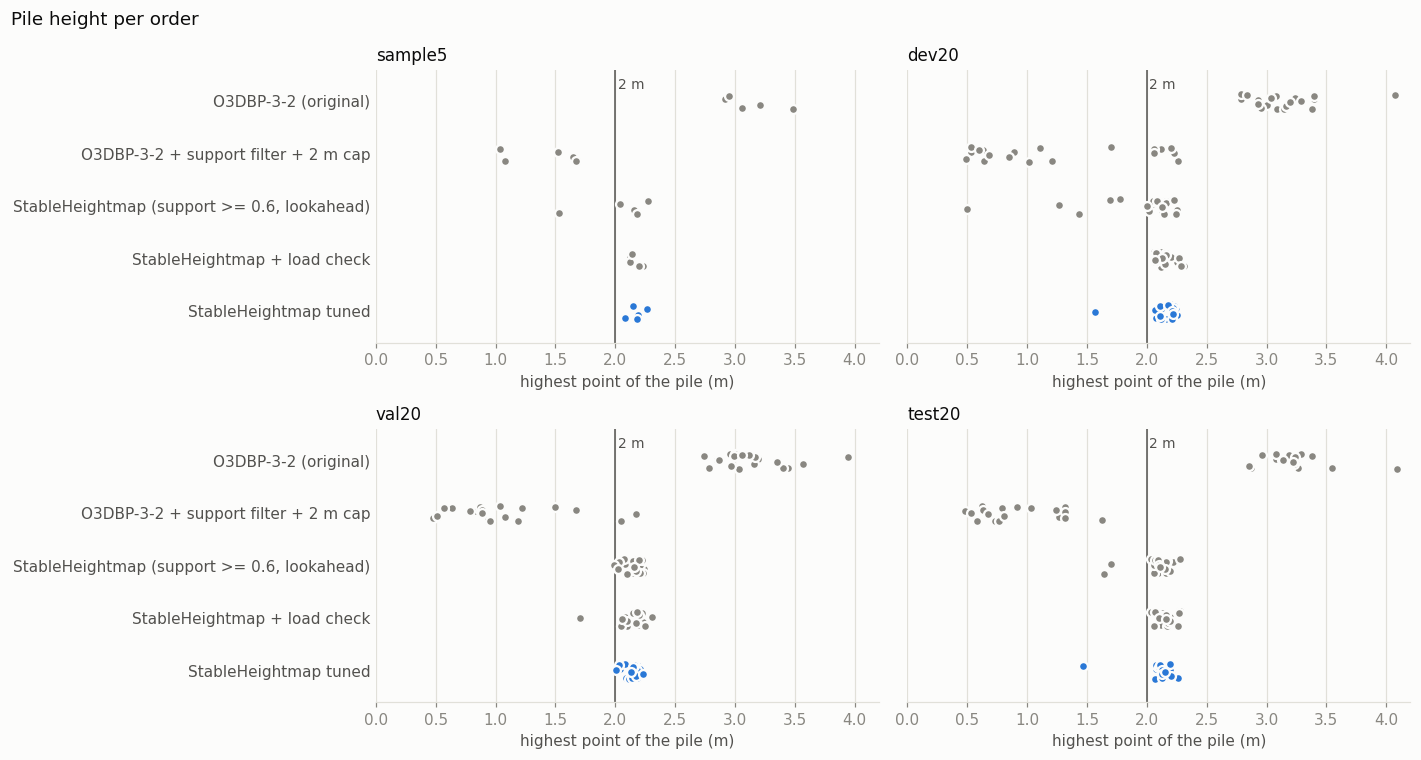

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
axes = axes.ravel()
for ax, dataset in zip(axes, DATASETS):
    for y, algorithm in enumerate(ALGORITHMS[::-1]):
        run = runs.get((dataset, algorithm))
        if run is None:
            continue
        heights = np.array([o["max_top_mm"] for o in run["per_order"] if o["placed"]]) / 1000
        jitter = (np.random.default_rng(0).random(len(heights)) - 0.5) * 0.3
        color = ACCENT if algorithm == "stable_heightmap_tuned" else MUTED
        ax.scatter(heights, y + jitter, s=34, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.axvline(2.0, color=INK_2, linewidth=1, zorder=2)
    ax.text(2.02, len(ALGORITHMS) - 0.55, "2 m", color=INK_2, fontsize=9, va="top")
    ax.set_yticks(range(len(ALGORITHMS)), names)
    ax.set_ylim(-0.6, len(ALGORITHMS) - 0.4)
    style_value_axis(ax, (0, 4.2), "highest point of the pile (m)")
    ax.set_title(dataset, loc="left", color=INK, fontsize=11)
fig.suptitle("Pile height per order", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()

## The 5 example orders

Counted items / items per order (*collapsed* = the pile was unstable, so 0 items count).

In [7]:
table = {}
for algorithm in ALGORITHMS:
    run = runs.get(("sample5", algorithm))
    if run is None:
        continue
    table[algorithm] = {
        o["order"]: (f'{o["counted"]}/{o["items"]}' if o["stable"] else f'collapsed ({o["placed"]} placed)')
        for o in run["per_order"]
    }
pd.DataFrame(table)

,o3dbp_original,o3dbp_constrained,stable_heightmap_basic,stable_heightmap_load_check,stable_heightmap_tuned
00100408,23/26,14/26,17/26,26/26,26/26
00100001,collapsed (41 placed),17/44,35/44,31/44,28/44
00100002,collapsed (34 placed),7/38,18/38,32/38,29/38
00100003,collapsed (31 placed),10/34,19/34,28/34,28/34
00100004,collapsed (58 placed),14/58,55/58,58/58,54/58


## Tuning log

**Round 1** tuned the hyperparameters on `dev20` only: the support threshold, the stability margin (also growing with
the height), and the score weights. The best configuration (T2) kept all 20 piles of `dev20` stable.

**Round 2.** On `val20`, T2 kept only 15 of 20 piles stable: the stability on `dev20` was partly luck. The collapses
on `val20` were all slender columns (boxes of 250-300 mm width stacked 1-1.4 m high on single boxes), which are
statically stable but sway in the simulation. Round 2 tested remedies on both `dev20` and `val20`: a hard limit on the
column slenderness (too restrictive: the orders run out of safe placements), a deeper search when the best placements
fail the load check, and a soft penalty for slender columns. The configuration with the best mean score over
`dev20` and `val20` (P0) became the default. `test20` was not used for any decision.

In [8]:
log = pd.DataFrame(json.loads((RESULTS / "tuning_log.json").read_text())).set_index(["round", "run"])
log["mean"] = log[["dev20 score", "val20 score"]].mean(axis=1, skipna=False).round(4)
log

change  \
round run                                                                
1     ms05_m20               load check, min_support 0.5, margin 20 mm   
      ms04_m20                                         min_support 0.4   
      ms03_m20       min_support 0.3 (= preset stable_heightmap_loa...   
      ms03_m30                           min_support 0.3, margin 30 mm   
      ms03_m40                                            margin 40 mm   
      m30_mpm30                      margin 30 mm + 30 mm per m height   
      m30_mpm60                      margin 30 mm + 60 mm per m height   
      m30_c05                              margin 30 mm, w_contact 0.5   
      m30_mpm40_c05                 w_contact 0.5 + 40 mm per m height   
      T1                        w_contact 0.5, w_flush 0.2, w_rise 0.5   
      T2             w_contact 1.0, w_flush 0.2, w_rise 0.5 (best o...   
      T3                        w_contact 1.0, w_flush 0.5, w_rise 0.5   
      T4                                       T3 + 20 mm per m height   
      T5                                       T1 + 20 mm per m height   
2     basic          no load check, min_support 0.6 (preset stable_...   
      K3                                      T2 + hard column limit 3   
      K3.5                                  T2 + hard column limit 3.5   
      K4                                      T2 + hard column limit 4   
      P0             T2 + progressive search (selected: best mean o...   
      P4                                      P0 + hard column limit 4   
      P5                                      P0 + hard column limit 5   
      W1                                  P0 + soft column penalty 0.1   
      W3                                  P0 + soft column penalty 0.3   

                     dev20 score dev20 stable  val20 score val20 stable  \
round run                                                                 
1     ms05_m20            0.6566        18/20          NaN         None   
      ms04_m20            0.6226        17/20          NaN         None   
      ms03_m20            0.6493        17/20       0.6703        16/20   
      ms03_m30            0.6917        18/20          NaN         None   
      ms03_m40            0.6541        18/20          NaN         None   
      m30_mpm30           0.6784        19/20          NaN         None   
      m30_mpm60           0.5498        20/20          NaN         None   
      m30_c05             0.7148        19/20          NaN         None   
      m30_mpm40_c05       0.6772        20/20          NaN         None   
      T1                  0.6881        17/20          NaN         None   
      T2                  0.8192        20/20       0.5451        15/20   
      T3                  0.7718        19/20          NaN         None   
      T4                  0.6675        18/20          NaN         None   
      T5                  0.6505        18/20          NaN         None   
2     basic               0.7160        20/20       0.6143        16/20   
      K3                  0.4175        20/20       0.3242        19/20   
      K3.5                0.4757        20/20       0.3571        19/20   
      K4                  0.5146        20/20       0.3857        19/20   
      P0                  0.8192        20/20       0.5637        15/20   
      P4                  0.5218        20/20       0.3857        19/20   
      P5                  0.5740        20/20       0.4385        18/20   
      W1                  0.7451        19/20       0.5747        16/20   
      W3                  0.7743        19/20       0.5923        16/20   

                       mean  
round run                    
1     ms05_m20          NaN  
      ms04_m20          NaN  
      ms03_m20       0.6598  
      ms03_m30          NaN  
      ms03_m40          NaN  
      m30_mpm30         NaN  
      m30_mpm60         NaN  
      m30_c05           NaN  
      m30_mpm40_c05     NaN  
      T

## Key numbers on the unseen orders (`test20`)

In [9]:
test = summary[summary.dataset == "test20"].set_index("algorithm")
base = test.loc["o3dbp_original", "score"]
for algorithm, row in test.iterrows():
    print(f"{LABELS[algorithm]:45s} score {row['score']:.3f} ({row['score'] - base:+.3f} vs. original)  "
          f"stable piles {row['stable orders']:>5}  placed {row['placed %']:5.1f} %")

O3DBP-3-2 (original)                          score 0.000 (+0.000 vs. original)  stable piles  0/20  placed  91.0 %
O3DBP-3-2 + support filter + 2 m cap          score 0.253 (+0.253 vs. original)  stable piles 20/20  placed  25.3 %
StableHeightmap (support >= 0.6, lookahead)   score 0.524 (+0.524 vs. original)  stable piles 17/20  placed  64.1 %
StableHeightmap + load check                  score 0.619 (+0.619 vs. original)  stable piles 17/20  placed  76.0 %
StableHeightmap tuned                         score 0.552 (+0.552 vs. original)  stable piles 16/20  placed  73.4 %


## Findings

1. **Stability is the dominant factor.** The original heuristic places almost all items, but most piles collapse in the
   simulation, so most orders count 0. The root cause of each collapse was an item with almost no support (2-37 %),
   created by shifting corner points outwards to 90 % of the target size without checking what is below.
2. **Constraints alone stop the collapses, but the corner points run out.** With a support filter and the 2 m cap,
   O3DBP-3-2 keeps the piles stable, but it stops after roughly a quarter to a third of the items because its corner
   points rarely offer a safe placement.
3. **Search everywhere, then check physics.** The new heuristic evaluates every aligned position on a 5 mm grid (exact
   for the environment's height map) and picks the best safe one; a one-step lookahead and a bonus for large items
   avoid dead ends. This more than doubles the score of the constrained O3DBP-3-2.
4. **Pile-level checks.** Boxes that are stable on their own can form a leaning tower; the load model propagates the
   loads through the pile and rejects such placements, which allows a lower support threshold and denser piles.
5. **Weight tuning on 20 orders did not transfer.** The tuned score weights (T2/P0) were best on `dev20`, but on the
   unseen `test20` the load-check configuration with the original weights scored higher (0.619 vs. 0.552); averaged over
   all 60 orders of `dev20`, `val20` and `test20` both score 0.645. The robust gains come from the structure of the
   algorithm (exhaustive search, support and center-of-mass check, load check, lookahead), not from fine-tuned weights.
   One collapse changes the score of 20 orders by about 0.05, so 20 orders are too few to tune stability-related weights.
6. **What remains.** 15-25 % of the piles still collapse on new orders, almost always slender columns of boxes that
   sway in the simulation, and orders that need more than 2 m even when packed densely cannot be placed completely.
   Next steps: a dynamic stability check (e.g. simulating candidate placements), interlocking layer patterns that avoid
   columns by construction, and tuning on more orders.